# Beispiel-Code Einführungsvorlesung

Zuerst installieren wir die notwendigen python Pakete mit Pip (falls noch nicht geschehen)

In [3]:
!pip install -r requirements.txt

Wir importieren notwendige Pakete sowie Hilfsfunktionen, welche für den Wettbewerb bereitgestellt werden

In [43]:
import matplotlib.pyplot as plt
import numpy as np
from wettbewerb import load_data
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
import joblib

Der Ordner mit den Trainingsdaten liegt in unserem Fall in einem Ordner im git-Repository. Wir laden die Trainingsdaten rein.

In [38]:
training_dataset_path = "datasets/training_dataset.mat"

Importiere die tabellarischen Daten bestehend aus einer Datenmatrix, Annotationen und den Namen der Features in der Datenmatrix

In [39]:
X, y, feature_names = load_data(training_dataset_path)
print(f"Dimensionen der Datenmatrix: {X.shape}") # (n_samples, n_hours, n_features)
print(f"Dimensionen der Annotationen: {y.shape}") # (n_samples, )
print(feature_names)

16254 Zeilen wurden geladen.
Dimensionen der Datenmatrix: (16254, 6, 36)
Dimensionen der Annotationen: (16254,)
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender']


Wir schauen uns die Datenmatrix an. Einträge können manchmal fehlen oder unrealistische Werte annehmen.

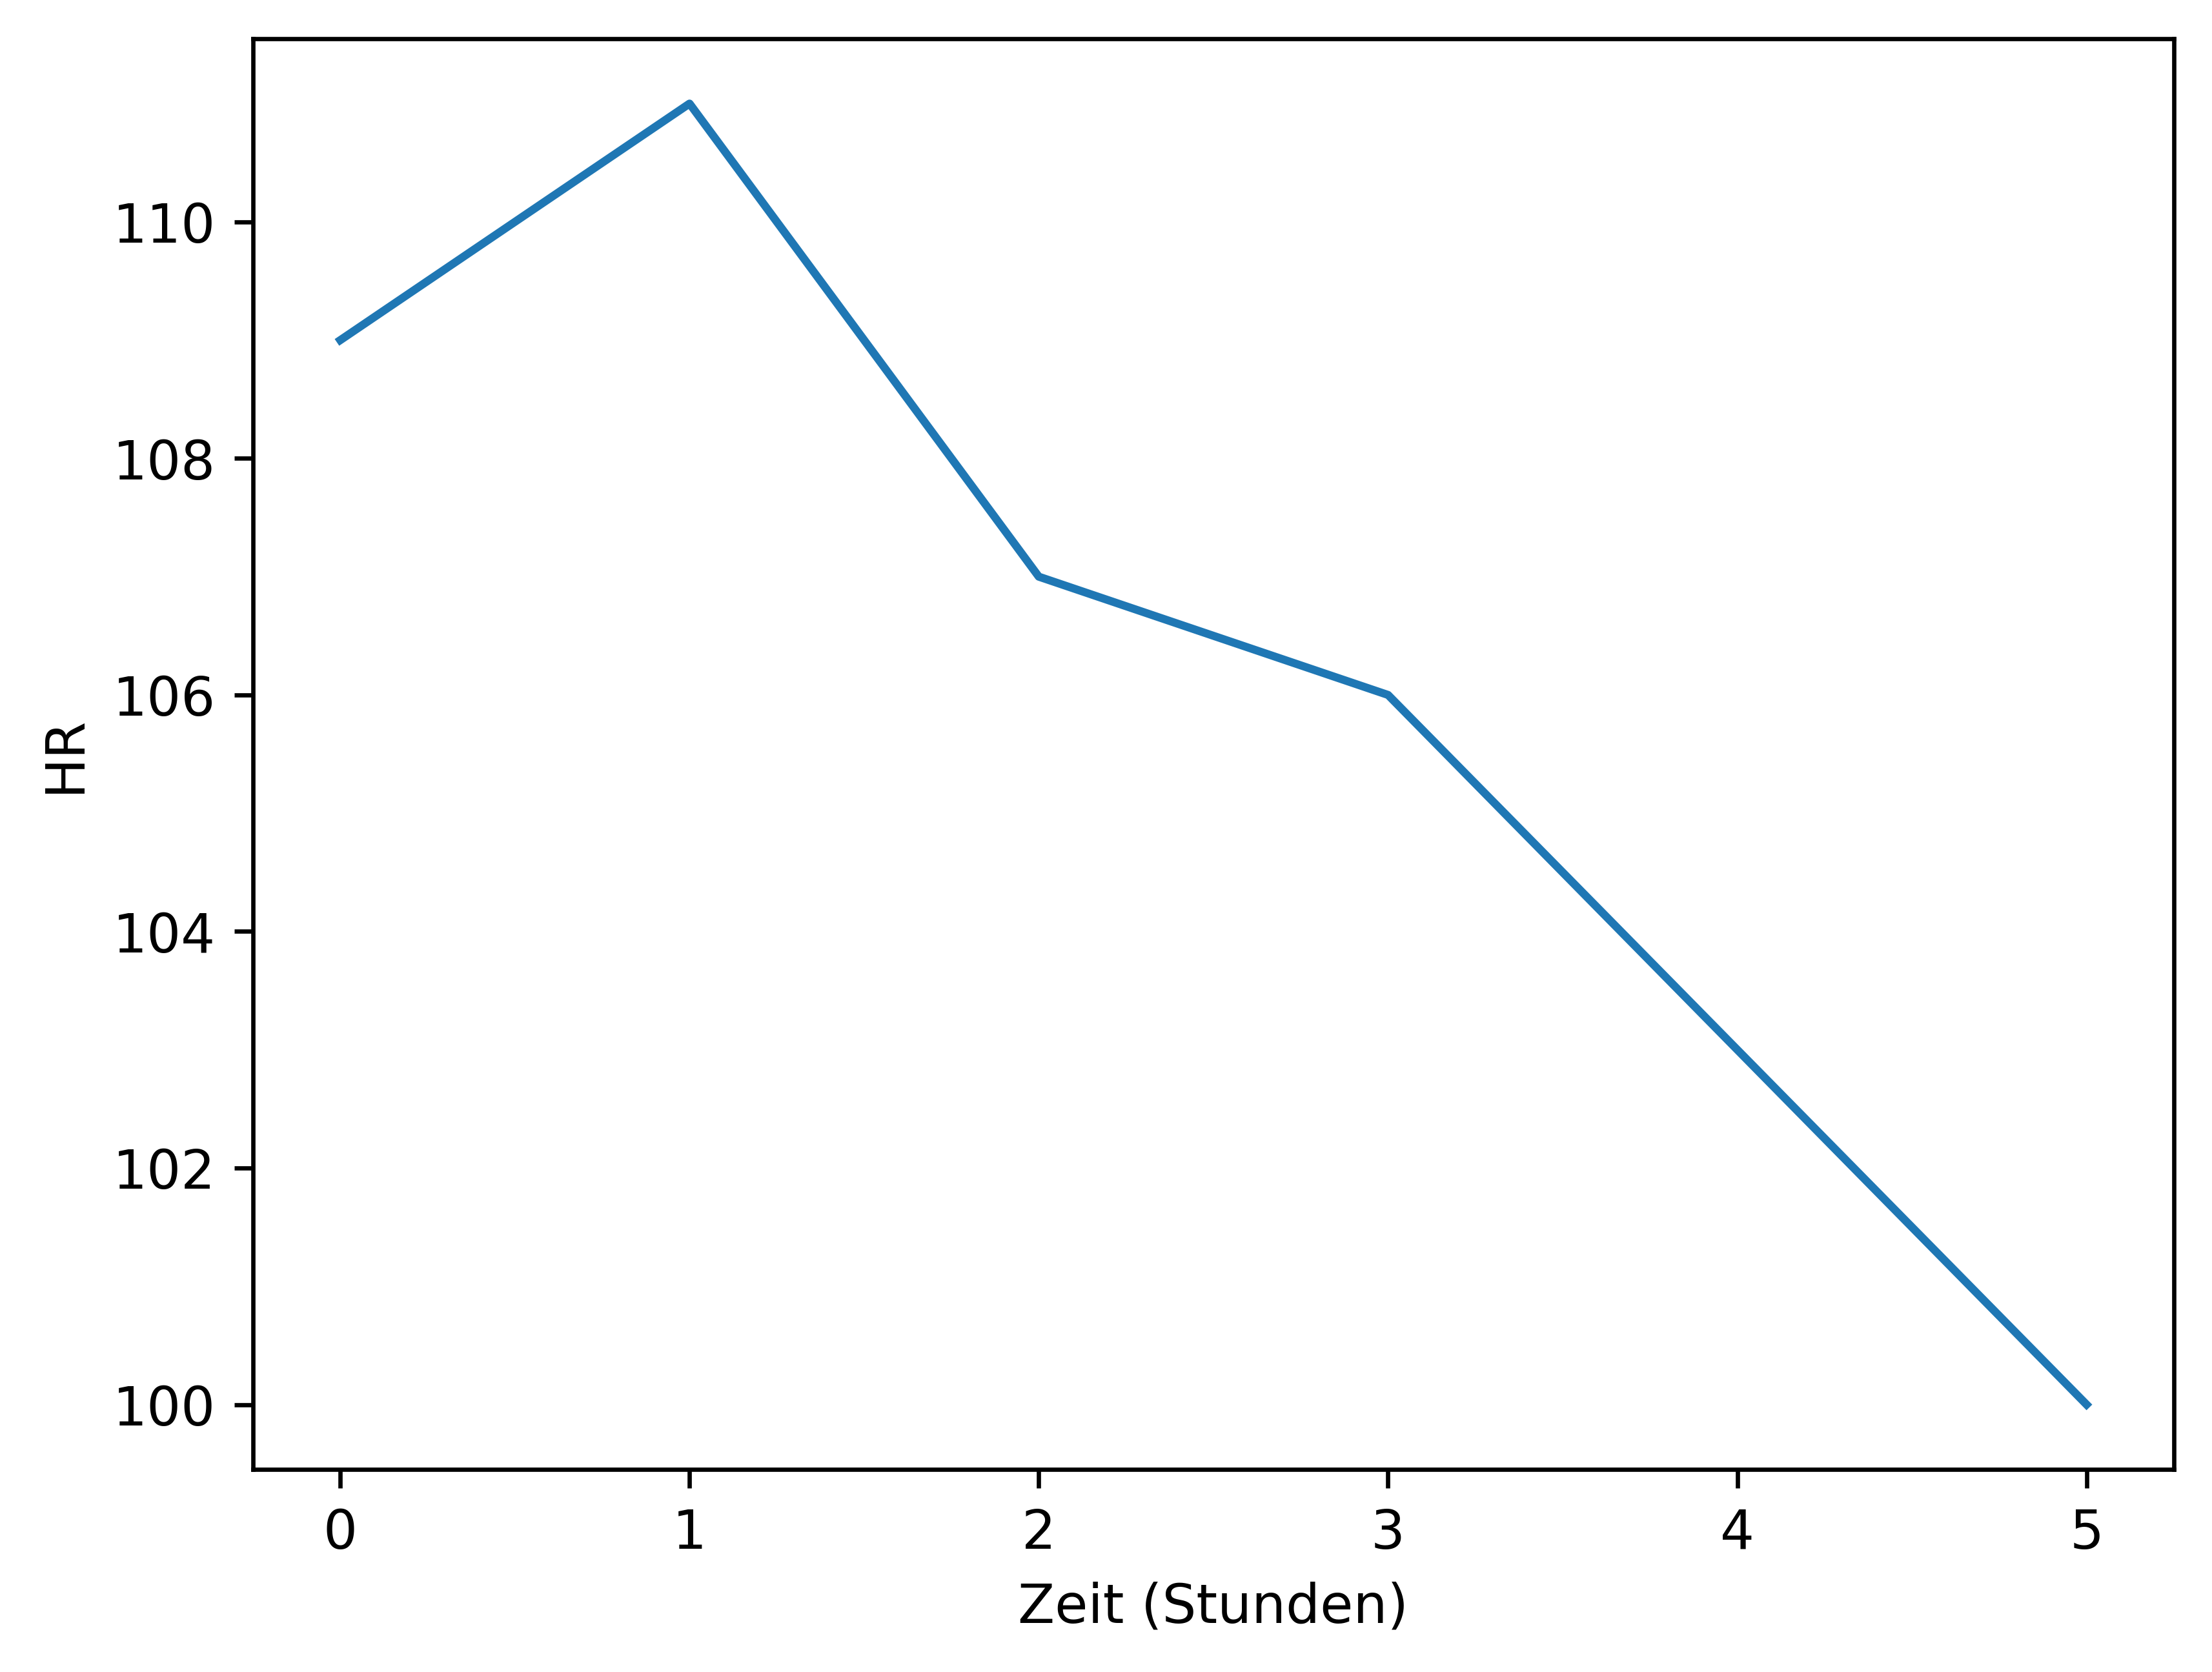

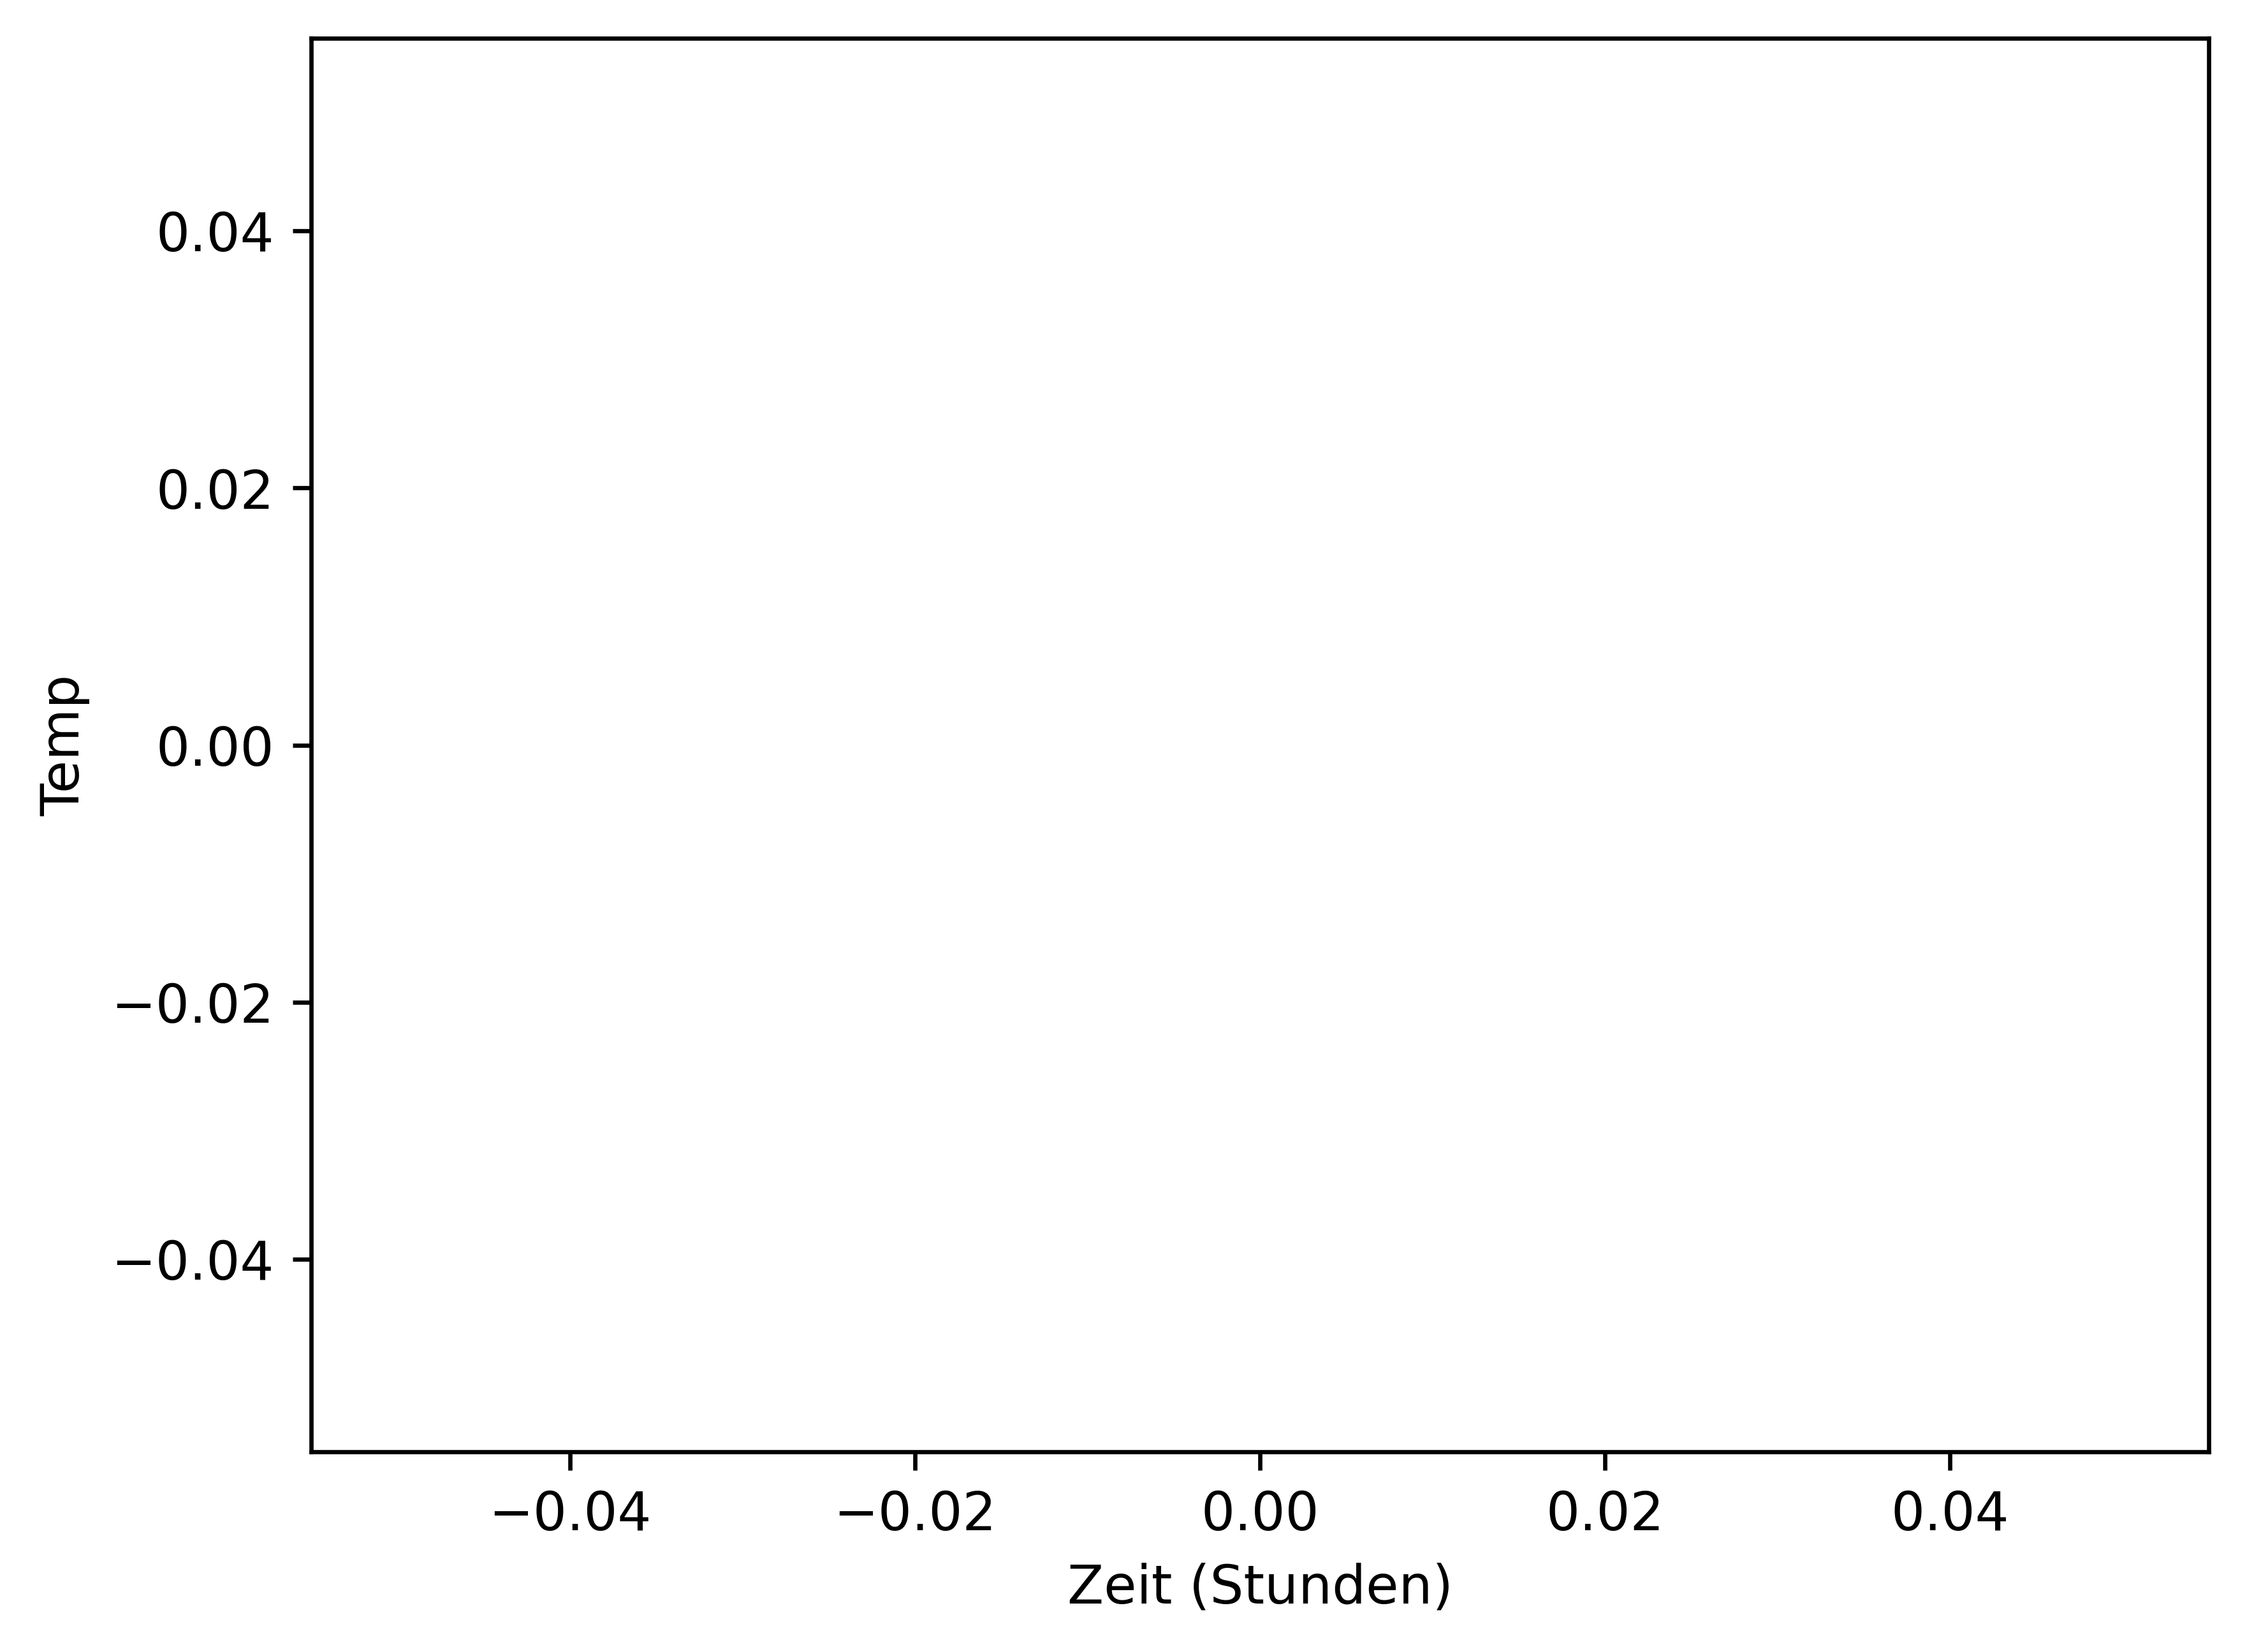

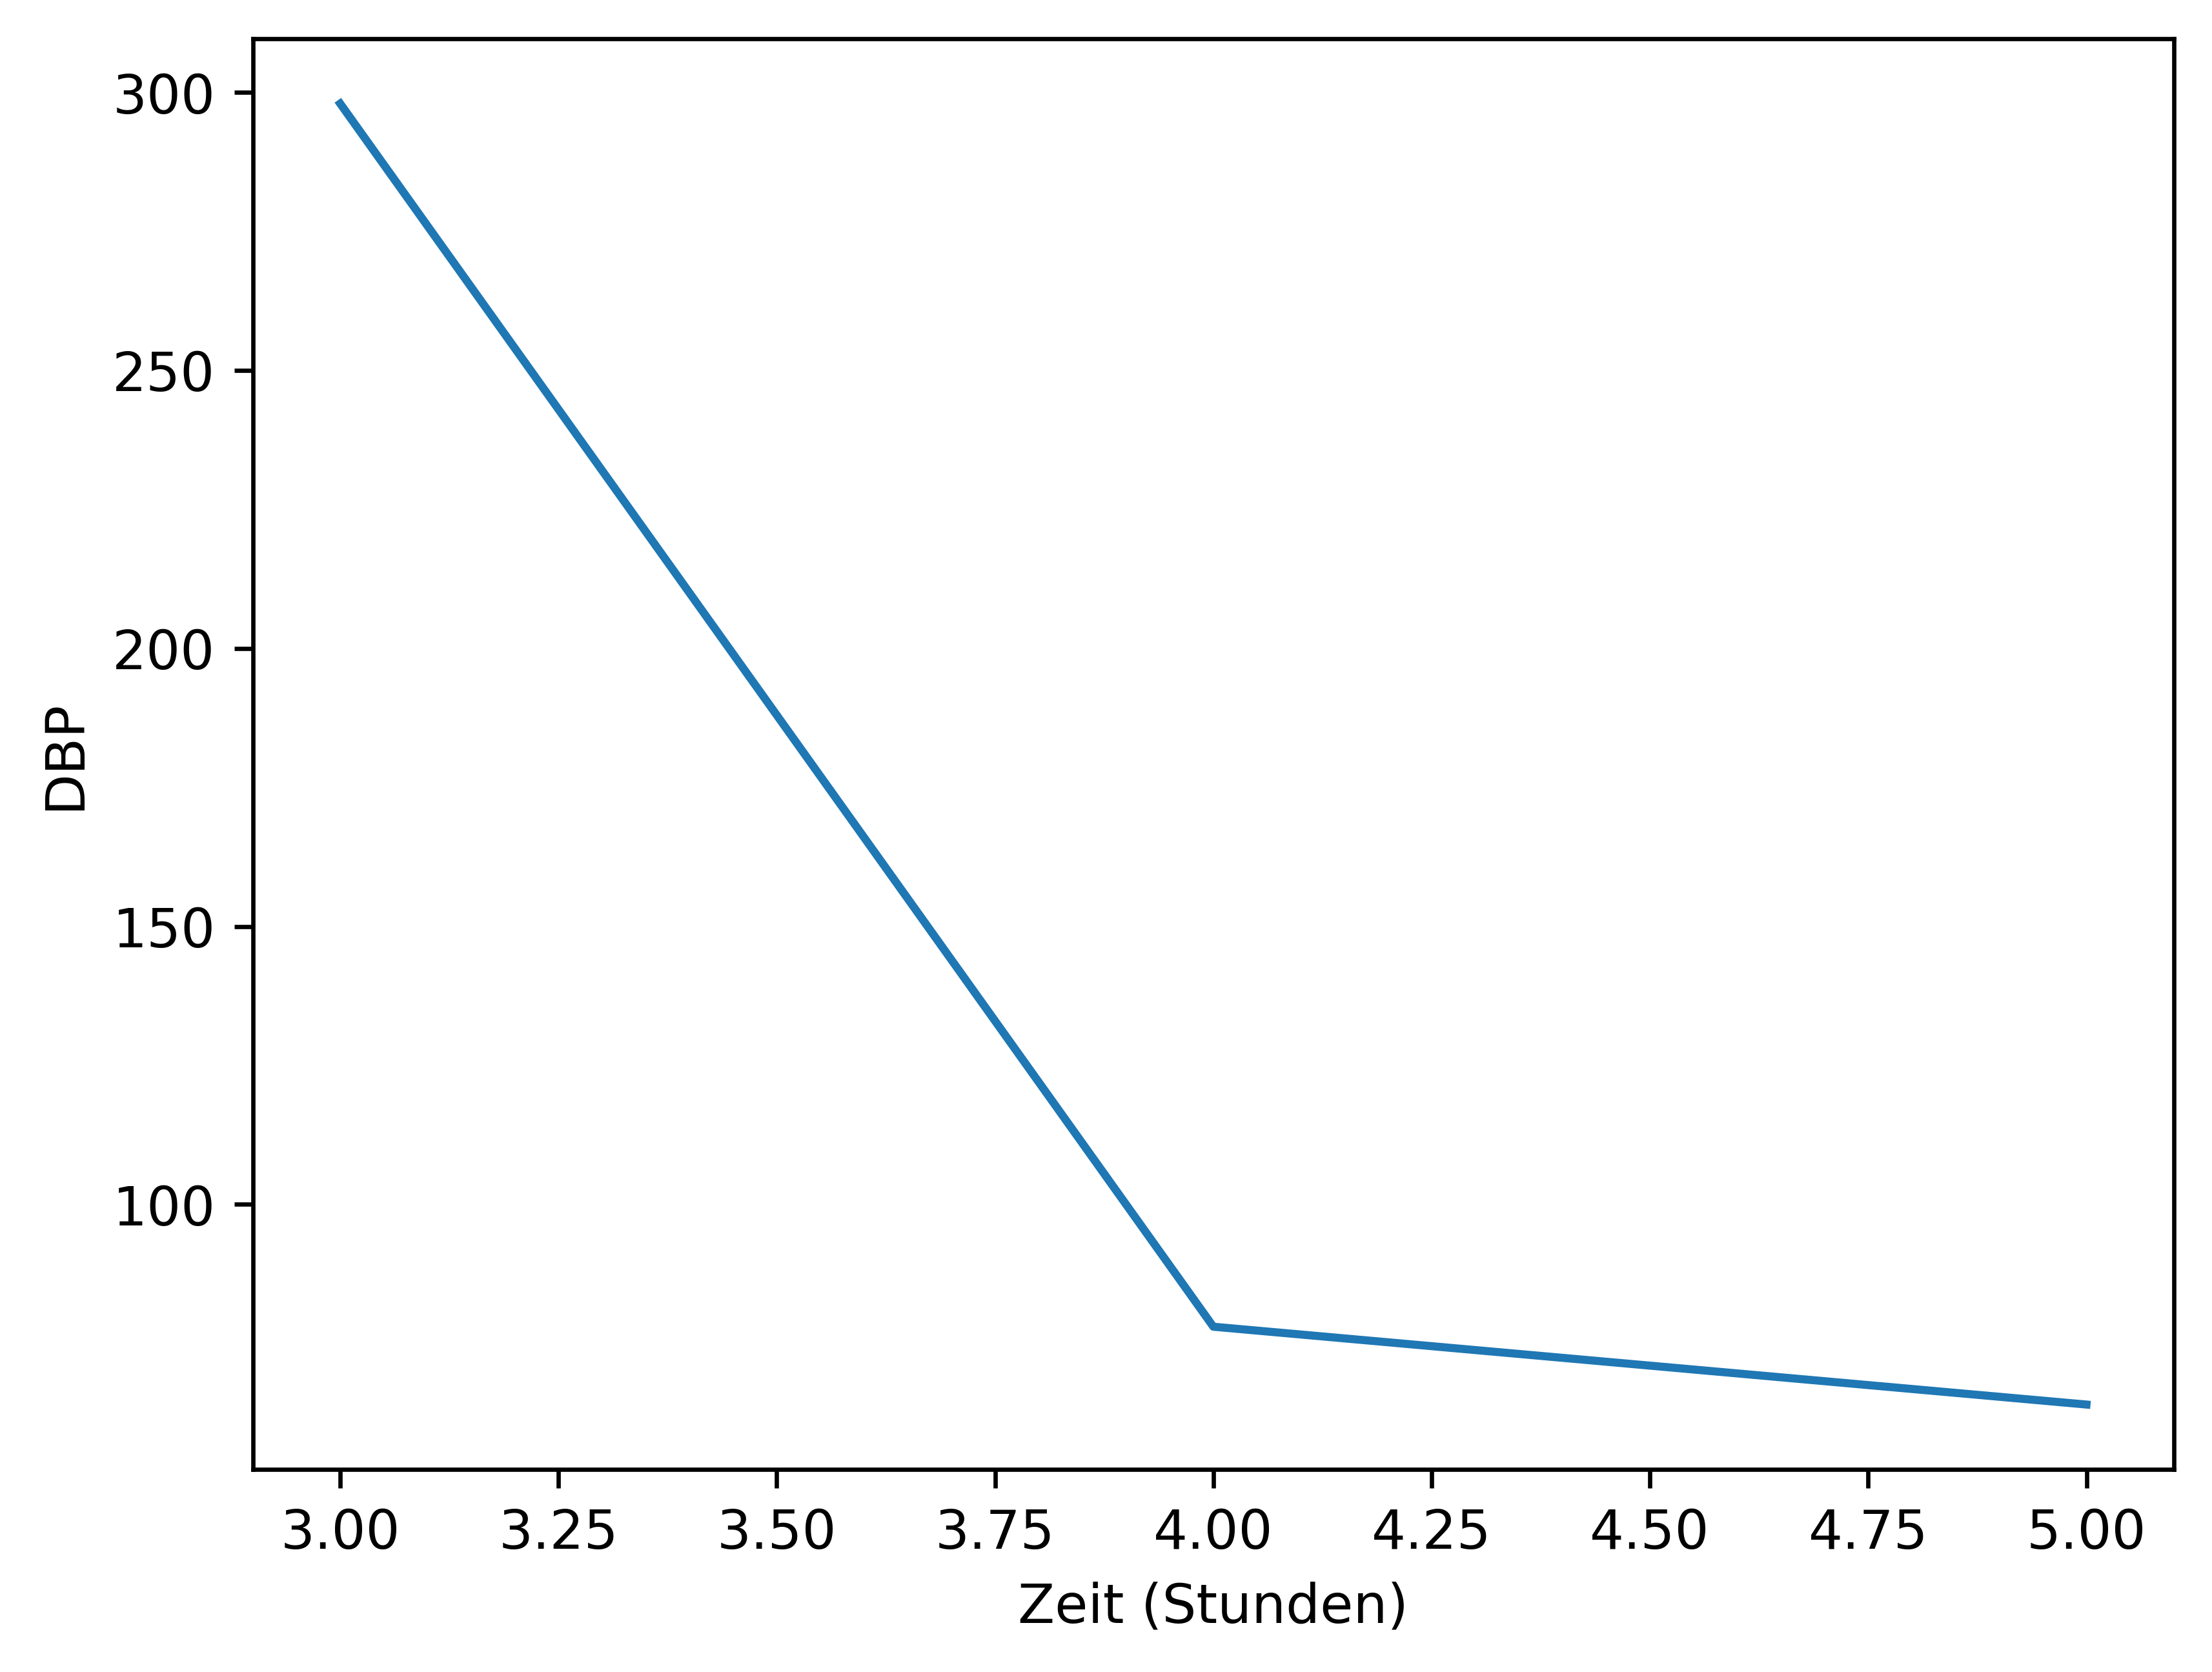

In [40]:
# Die Herzrate ist komplett vorhanden bei Patient 3
patient_idx = 3
feature_idx = 0 

plt.figure(dpi=600)
plt.plot(X[patient_idx, :, feature_idx]) 
plt.xlabel("Zeit (Stunden)")
plt.ylabel(feature_names[feature_idx])
plt.show()

# Die Temperatur fehlt bei Patient 0
patient_idx = 0
feature_idx = 2 

plt.figure(dpi=600)
plt.plot(X[patient_idx, :, feature_idx]) 
plt.xlabel("Zeit (Stunden)")
plt.ylabel(feature_names[feature_idx])
plt.show()

# Patient 13468 hat einen diastolischen Blutdruck von ca. 300 mmHg (Und es fehlen die ersten zwei Stunden)
patient_idx = 13468
feature_idx = 5 

plt.figure(dpi=600)
plt.plot(X[patient_idx, :, feature_idx]) 
plt.xlabel("Zeit (Stunden)")
plt.ylabel(feature_names[feature_idx])
plt.show()

## Vorhersage einer Sepsis
Das zentrale Ziel des Wettbewerbs ist die Vorhersage von Sepsis. Wir verwenden im folgenden ein lineares Klassifikationsmodel (Logistic Regression). Man kann damit in einigen Fällen bereits sehr gute Ergebnisse erzielen, allerdings gibt es auch einge Fälle in denen dies nicht funktioniert. Das zu lösen ist eure Aufgabe im Verlaufe des Wettbewerbs.

In [48]:
# Wir teilen unseren Datensatz in einem Trainings- und Validierungsdatensatz auf, um die Generalisierbarkeit unseres Modells bewerten zu können
# Wir nutzen die "stratify" Funktion von Scikit-learn, damit beide Datensätze fast dasselbe Verhältnis von positiven zu negativen Fälle haben.
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

# Wir ignorieren erstmal die zeitabhängige Struktur und packen die Daten aus den 6 Stunden alle zusammen in einer Zeile 
X_train = X_train.reshape(X_train.shape[0], -1) # Shape: (n_samples_train, n_hours*n_features)
X_train[np.isnan(X_train)] = 0 # Wir ersetzen die nan Werte mit 0

X_val = X_val.reshape(X_val.shape[0], -1) # Shape: (n_samples_val, n_hours*n_features)
X_val[np.isnan(X_val)] = 0 # Wir ersetzen die nan Werte mit 0

# Wir erstellen das Modell und trainieren es
logreg = LogisticRegression()
logreg.fit(X_train, y_train)

# Wir erstellen Vorhersagen mit dem Modell für den Trainings- und Validierungsdatensatz
preds_train = logreg.predict(X_train)
preds_val = logreg.predict(X_val)

# Wir berechnen den F1 Score für den Trainings- und Validierungsdatensatz
f1_score_train = f1_score(y_true=y_train, y_pred=preds_train)
f1_score_val = f1_score(y_true=y_val, y_pred=preds_val)

print(f"F1-Score Trainingsdatensatz: {f1_score_train:.2f}")
print(f"F1-Score Validierungsdatensatz: {f1_score_val:.2f}")

# Wir speichern das Modell ab, damit wir es später verwenden können
joblib.dump(logreg, "model.pkl");

# Fragen an euch:
# Warum konvergiert der Algorithmus nicht?
# Warum ist der F1-Score fast gleich für den Trainings- und Validierungsdatensatz?

F1-Score Trainingsdatensatz: 0.65
F1-Score Validierungsdatensatz: 0.62


c:\Users\JadHa\anaconda3\envs\nmap23\lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Wir schauen das Ergebnis für den Validierungsdatensatz als Confusion Matrix an. Was fällt euch auf?

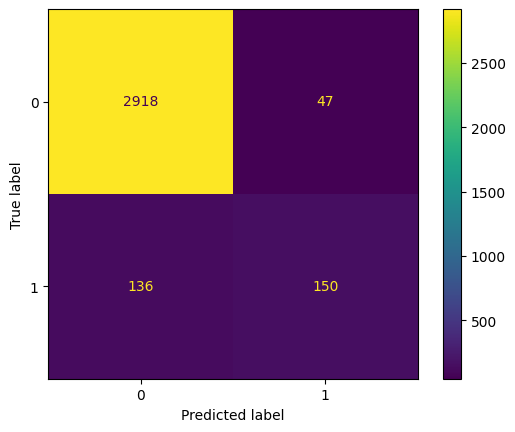

In [46]:
disp = ConfusionMatrixDisplay.from_predictions(y_true=y_val, y_pred=preds_val)